# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
# Load the cleaned data saved in Part One
df = pd.read_csv("data/AviationData_cleaned.csv", low_memory=False)
print(df.shape)
df.head()

(57791, 32)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.Passengers,Fatal.Serious.Fraction,Destroyed,Make.Model
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,NaN,NaN,ONP,NEWPORT MUNICIPAL,...,1.0,3.0,VMC,Approach,Probable Cause,NaN,4.0,0.0,0,Cessna 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,NaN,NaN,3YR,MUNICIPAL,...,0.0,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0,Cessna 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,NaN,NaN,78Y,RANKIN,...,0.0,1.0,VMC,Takeoff,Probable Cause,NaN,1.0,0.0,0,Cessna 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,NaN,NaN,CCB,CABLE,...,2.0,0.0,VMC,Approach,Probable Cause,NaN,2.0,0.0,0,Piper PA-28R-200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,NaN,NaN,SPRINGBROOK,...,0.0,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0,Cessna 140


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [3]:
# Separate plane types by the number of people on board (threshold = 20)
df["Plane.Size"] = np.where(df["Total.Passengers"] >= 20, "Large", "Small")

small = df[df["Plane.Size"] == "Small"]
large = df[df["Plane.Size"] == "Large"]

print(df["Plane.Size"].value_counts())

Plane.Size
Small    57184
Large      607
Name: count, dtype: int64


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

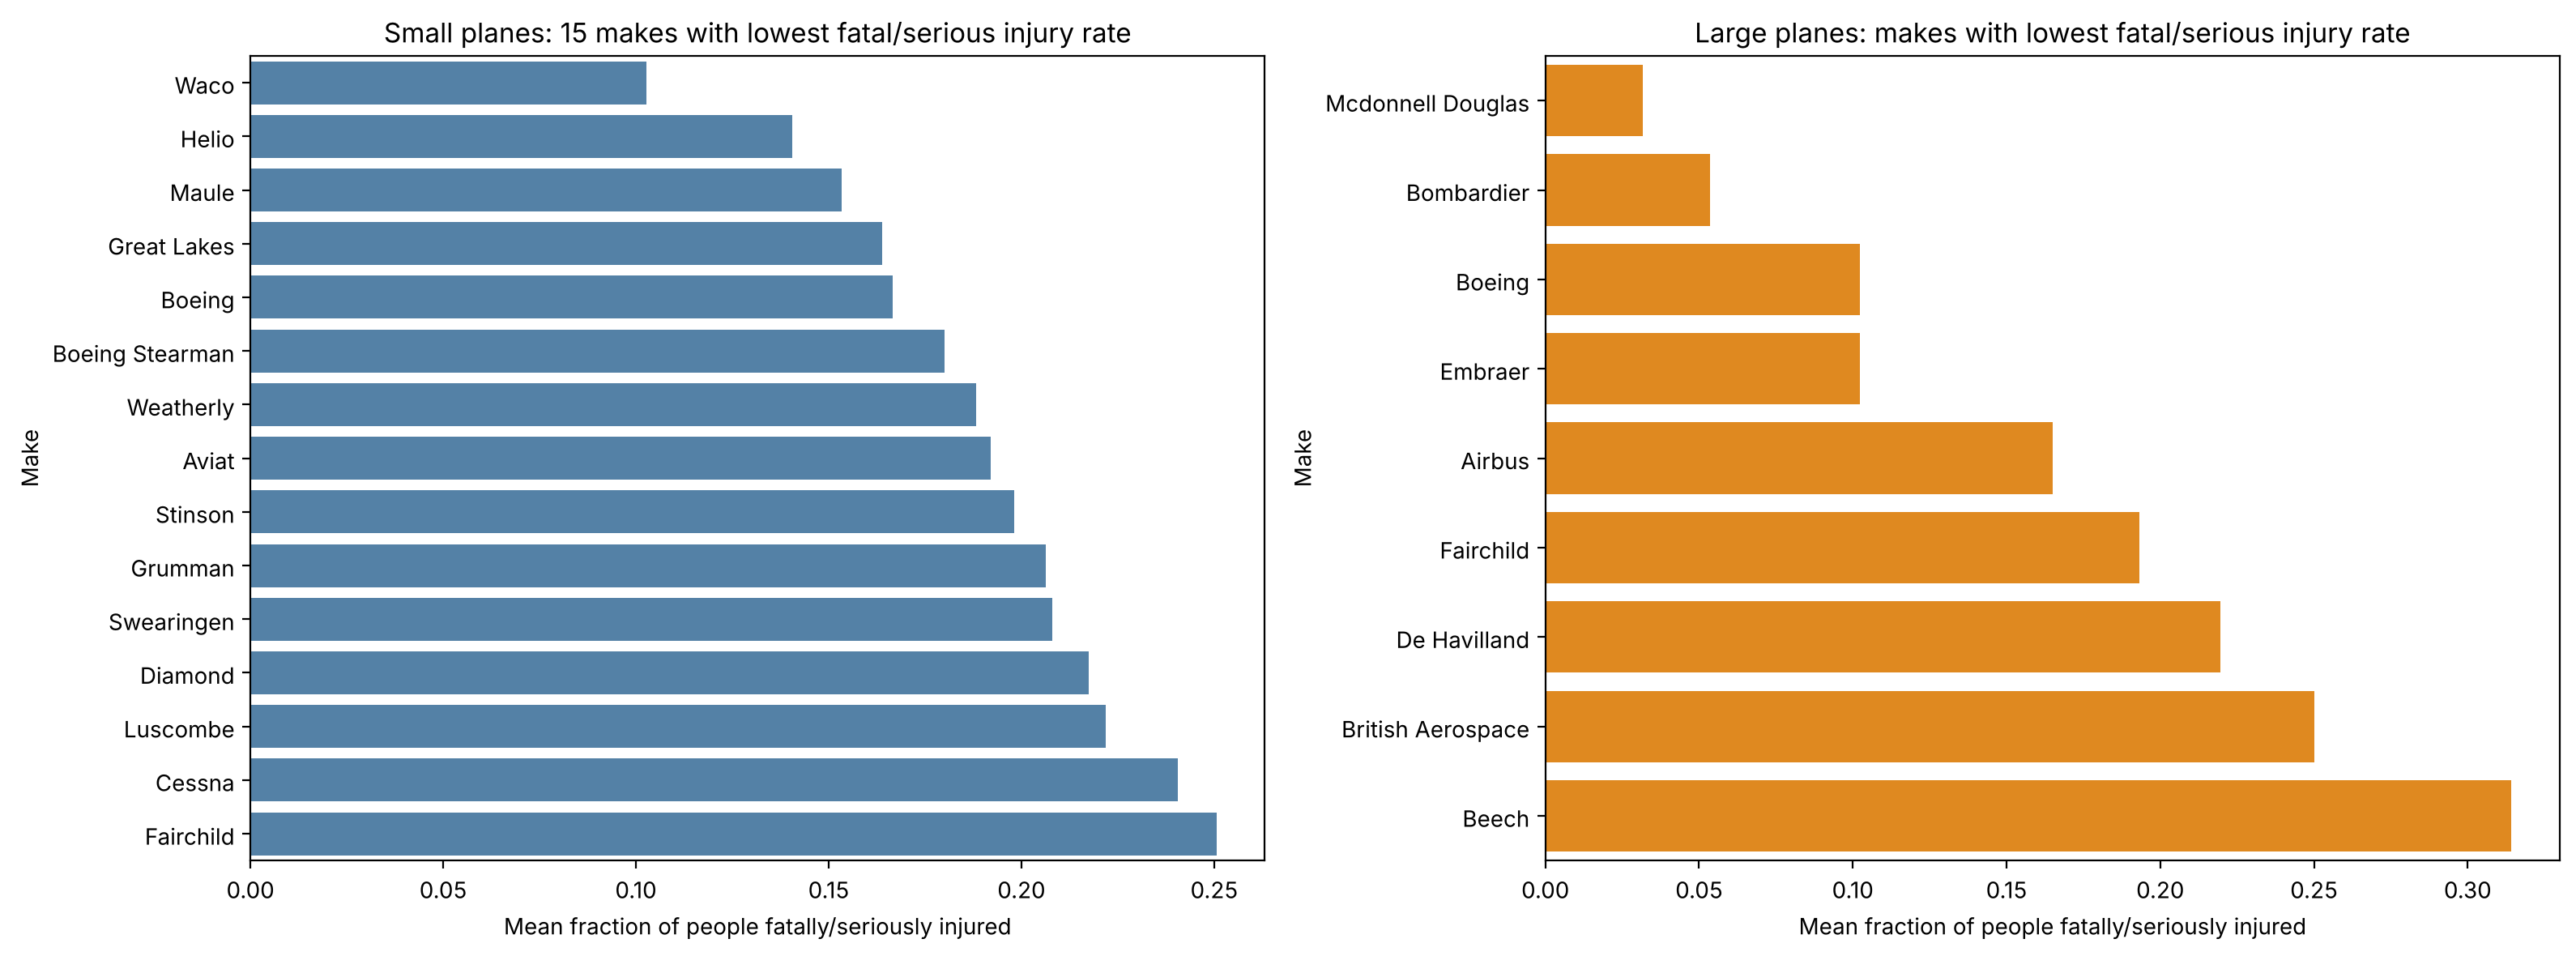

,Accidents,Mean_Fatal_Serious,Destroyed_Rate
Make,,,
Waco,138,0.103,0.087
Helio,105,0.141,0.124
Maule,569,0.153,0.093
Great Lakes,58,0.164,0.138
Boeing,202,0.167,0.109
Boeing Stearman,50,0.180,0.100
Weatherly,85,0.188,0.212
Aviat,216,0.192,0.069
Stinson,421,0.198,0.133


,Accidents,Mean_Fatal_Serious,Destroyed_Rate
Make,,,
Mcdonnell Douglas,41,0.032,0.122
Bombardier,71,0.054,0.056
Boeing,279,0.102,0.097
Embraer,46,0.102,0.087
Airbus,73,0.165,0.164
Fairchild,13,0.193,0.308
De Havilland,33,0.219,0.242
British Aerospace,16,0.250,0.250
Beech,18,0.314,0.444


In [4]:
# Summary statistics by Make, keeping only makes with enough accidents to be reliable
def make_summary(data, min_accidents):
    summary = data.groupby("Make").agg(
        Accidents=("Event.Id", "count"),
        Mean_Fatal_Serious=("Fatal.Serious.Fraction", "mean"),
        Destroyed_Rate=("Destroyed", "mean"),
    )
    return summary[summary["Accidents"] >= min_accidents]

small_makes = make_summary(small, 50)   # small planes: at least 50 accidents
large_makes = make_summary(large, 10)   # large planes: at least 10 accidents (fewer records)

# 15 makes with the lowest mean fatal/serious injury fraction in each group
small_top15 = small_makes.sort_values("Mean_Fatal_Serious").head(15)
large_top15 = large_makes.sort_values("Mean_Fatal_Serious").head(15)

# Side-by-side bar charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=small_top15["Mean_Fatal_Serious"], y=small_top15.index, ax=axes[0], color="steelblue")
axes[0].set_title("Small planes: 15 makes with lowest fatal/serious injury rate")
axes[0].set_xlabel("Mean fraction of people fatally/seriously injured")
axes[0].set_ylabel("Make")

sns.barplot(x=large_top15["Mean_Fatal_Serious"], y=large_top15.index, ax=axes[1], color="darkorange")
axes[1].set_title("Large planes: makes with lowest fatal/serious injury rate")
axes[1].set_xlabel("Mean fraction of people fatally/seriously injured")
axes[1].set_ylabel("Make")

plt.tight_layout()
plt.show()

display(small_top15.round(3))
display(large_top15.round(3))

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

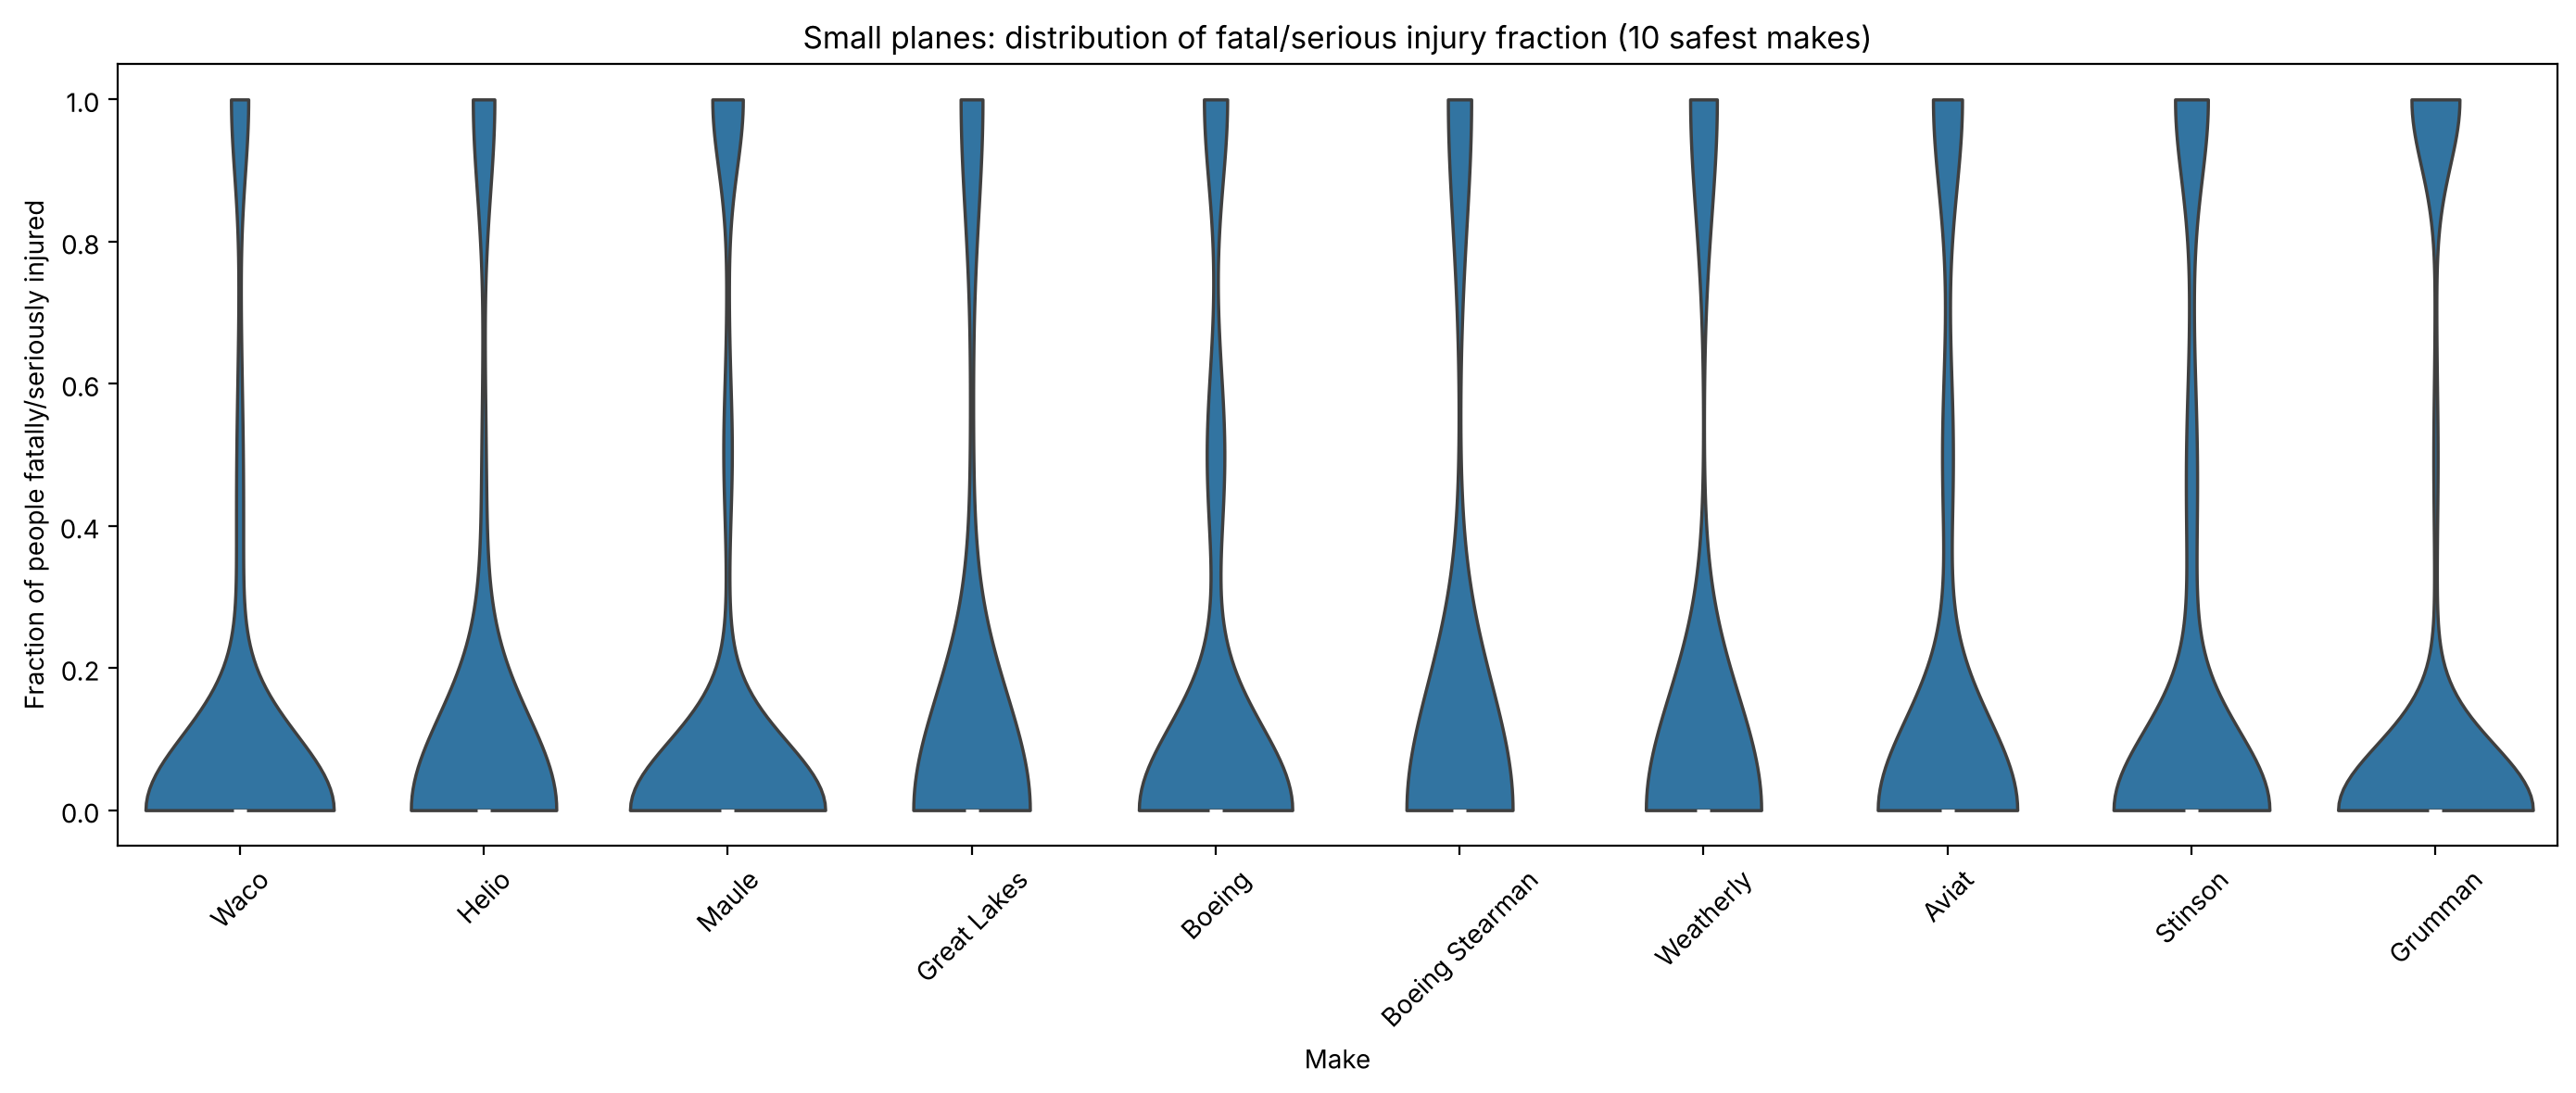

In [5]:
# 10 small-plane makes with the lowest mean fatal/serious injury fraction
top10_small = small_makes.sort_values("Mean_Fatal_Serious").head(10).index

plt.figure(figsize=(14, 6))
sns.violinplot(data=small[small["Make"].isin(top10_small)],
               x="Make", y="Fatal.Serious.Fraction", order=top10_small, cut=0)
plt.title("Small planes: distribution of fatal/serious injury fraction (10 safest makes)")
plt.xlabel("Make")
plt.ylabel("Fraction of people fatally/seriously injured")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

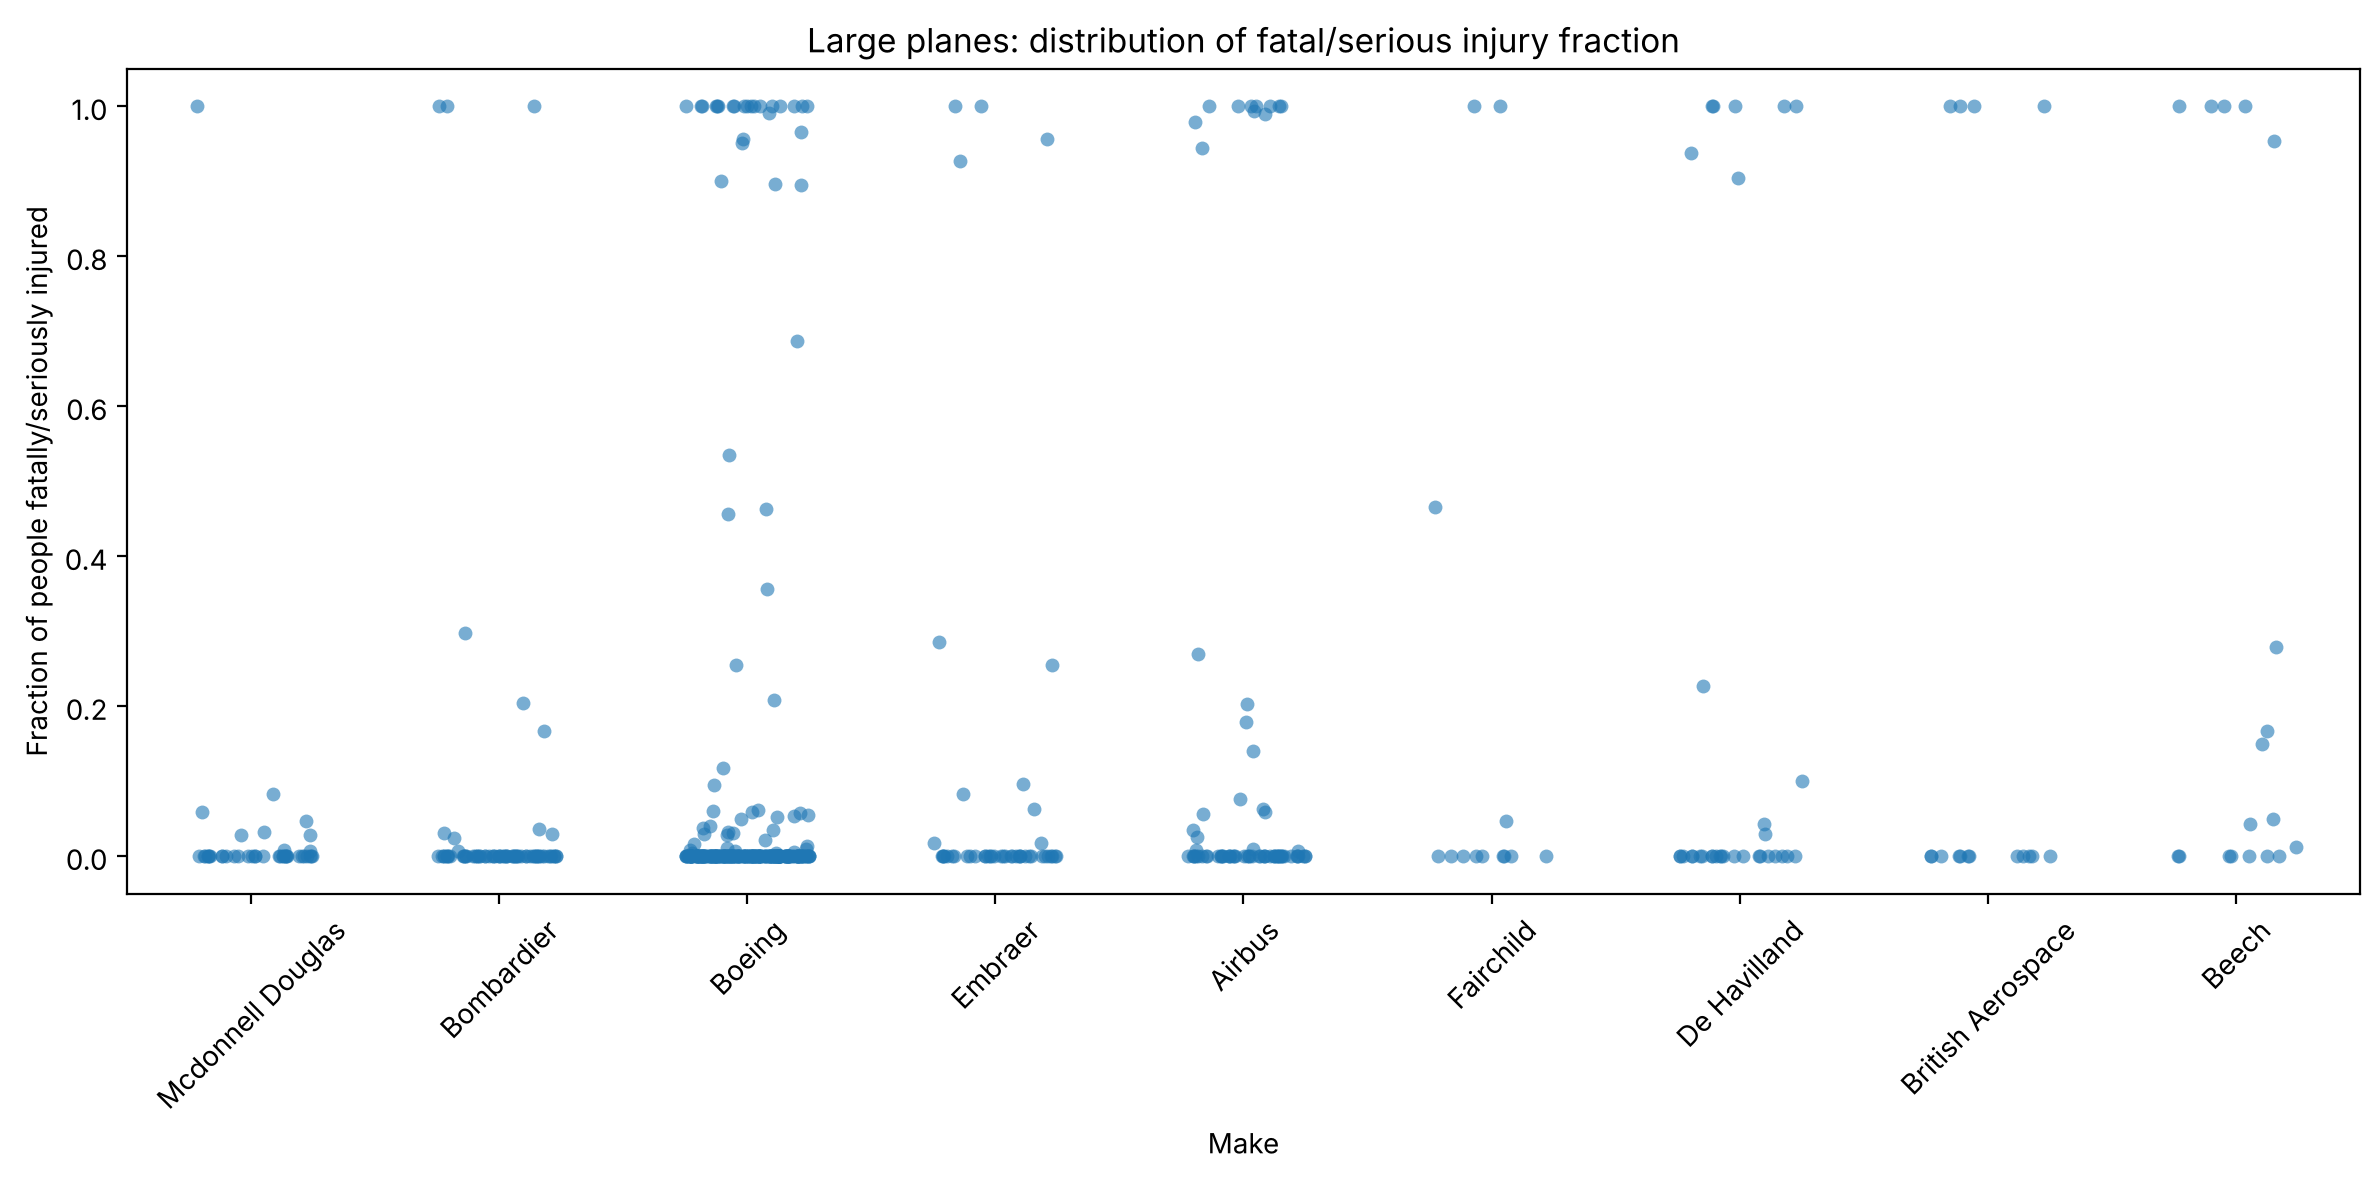

In [6]:
# Large-plane makes with the lowest mean fatal/serious injury fraction (only 9 qualify)
top10_large = large_makes.sort_values("Mean_Fatal_Serious").head(10).index

plt.figure(figsize=(12, 6))
sns.stripplot(data=large[large["Make"].isin(top10_large)],
              x="Make", y="Fatal.Serious.Fraction", order=top10_large,
              jitter=0.25, alpha=0.6)
plt.title("Large planes: distribution of fatal/serious injury fraction")
plt.xlabel("Make")
plt.ylabel("Fraction of people fatally/seriously injured")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

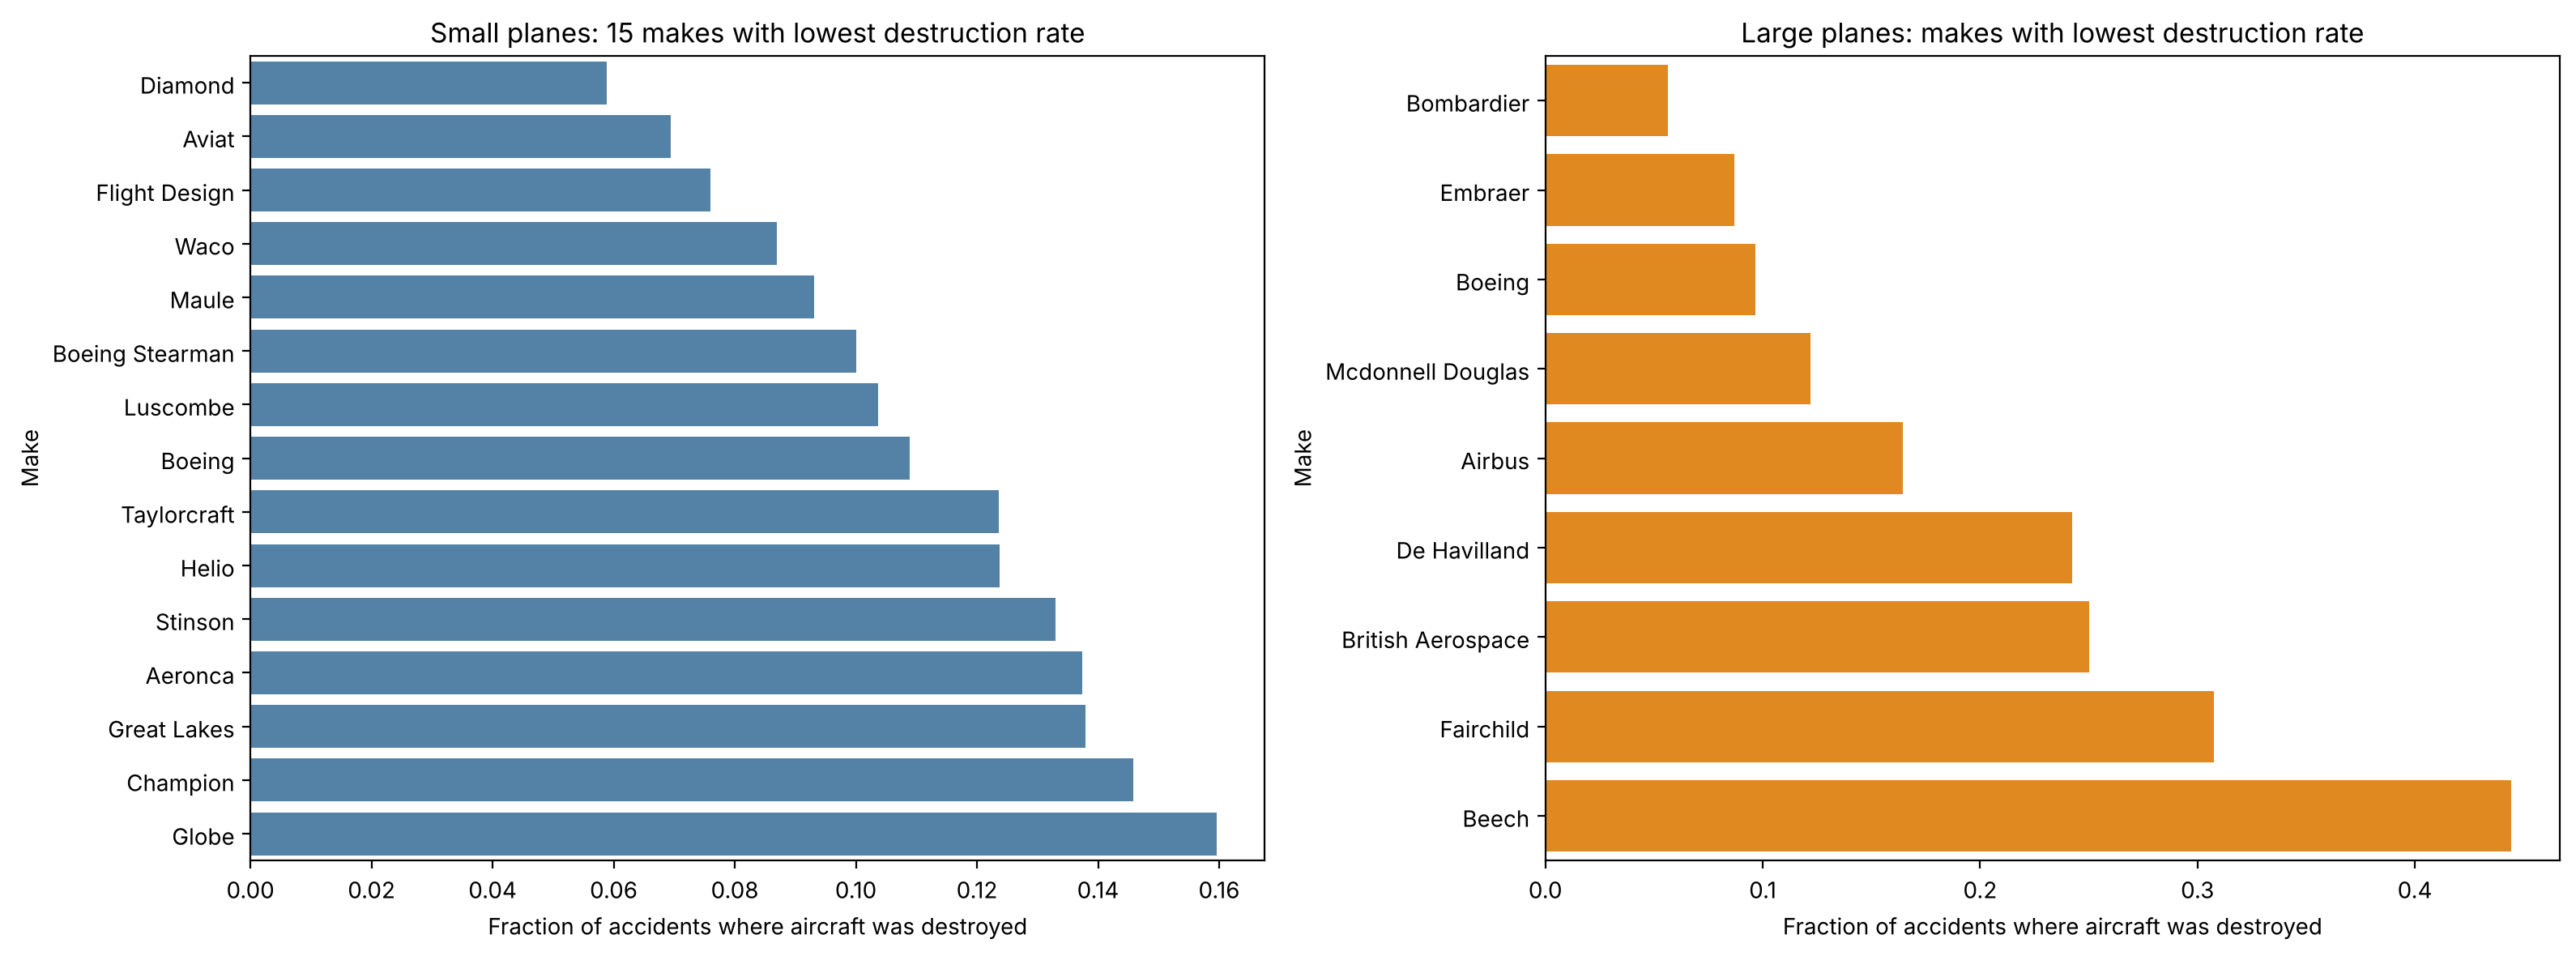

,Accidents,Mean_Fatal_Serious,Destroyed_Rate
Make,,,
Diamond,136,0.218,0.059
Aviat,216,0.192,0.069
Flight Design,79,0.354,0.076
Waco,138,0.103,0.087
Maule,569,0.153,0.093
Boeing Stearman,50,0.180,0.100
Luscombe,386,0.222,0.104
Boeing,202,0.167,0.109
Taylorcraft,364,0.294,0.124


,Accidents,Mean_Fatal_Serious,Destroyed_Rate
Make,,,
Bombardier,71,0.054,0.056
Embraer,46,0.102,0.087
Boeing,279,0.102,0.097
Mcdonnell Douglas,41,0.032,0.122
Airbus,73,0.165,0.164
De Havilland,33,0.219,0.242
British Aerospace,16,0.250,0.250
Fairchild,13,0.193,0.308
Beech,18,0.314,0.444


In [7]:
# Destruction rate by Make: fraction of accidents where the aircraft was destroyed
small_destroyed = small_makes.sort_values("Destroyed_Rate").head(15)
large_destroyed = large_makes.sort_values("Destroyed_Rate").head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=small_destroyed["Destroyed_Rate"], y=small_destroyed.index, ax=axes[0], color="steelblue")
axes[0].set_title("Small planes: 15 makes with lowest destruction rate")
axes[0].set_xlabel("Fraction of accidents where aircraft was destroyed")
axes[0].set_ylabel("Make")

sns.barplot(x=large_destroyed["Destroyed_Rate"], y=large_destroyed.index, ax=axes[1], color="darkorange")
axes[1].set_title("Large planes: makes with lowest destruction rate")
axes[1].set_xlabel("Fraction of accidents where aircraft was destroyed")
axes[1].set_ylabel("Make")

plt.tight_layout()
plt.show()

display(small_destroyed.round(3))
display(large_destroyed.round(3))

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

### Discussion: Make recommendations

**Small aircraft (fewer than 20 people on board)**
- **Maule** stands out: low fatal/serious injury fraction (≈0.15) and low destruction rate (≈0.09), backed by a large sample (569 accidents).
- **Aviat** (≈0.19 injury, ≈0.07 destroyed, 216 accidents) and **Waco** (≈0.10 injury, ≈0.09 destroyed, 138 accidents) also perform well on both measures.
- **Diamond** has the lowest destruction rate of all small makes (≈0.06), though its injury fraction (≈0.22) is closer to average.
- **Recommendation:** Maule, Aviat, Waco and Diamond are the strongest small-aircraft makes on both safety measures.

**Large aircraft (20 or more people on board)**
- **Bombardier** is the best all-round performer: very low injury fraction (≈0.05) and the lowest destruction rate (≈0.06).
- **Boeing** and **Embraer** both have low injury fractions (≈0.10) and low destruction rates (≈0.09–0.10). Boeing's result is the most reliable, being based on 279 accidents.
- **McDonnell Douglas** has the lowest injury fraction (≈0.03) but a higher destruction rate (≈0.12), and many of its models are no longer in production.
- **Airbus** performs noticeably worse (≈0.17 injury, ≈0.16 destroyed); **Beech** and **Fairchild** are worst but have very few large-plane records.
- **Recommendation:** Bombardier, Boeing and Embraer for large passenger aircraft.

**Comments on the statistics and distributions**
- Injury outcomes are strongly "all or nothing" for small planes (violin plots concentrated at 0 and 1), so a make's mean injury fraction mostly reflects how often it has a severe crash.
- For large planes, most accidents injure few people (strip plot concentrated at 0); severe crashes are rare.
- Only makes with enough records were compared (≥50 accidents for small, ≥10 for large). Large-plane results rely on far fewer records (607 in total), so they are less certain than the small-plane results.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

,Accidents,Mean_Fatal_Serious,Destroyed_Rate
Make.Model,,,
Boeing 777,16,0.000,0.062
Bombardier CL-600-2B19,28,0.011,0.000
Boeing 767,15,0.087,0.067
Boeing 737,97,0.134,0.113
Airbus A320,11,0.274,0.273


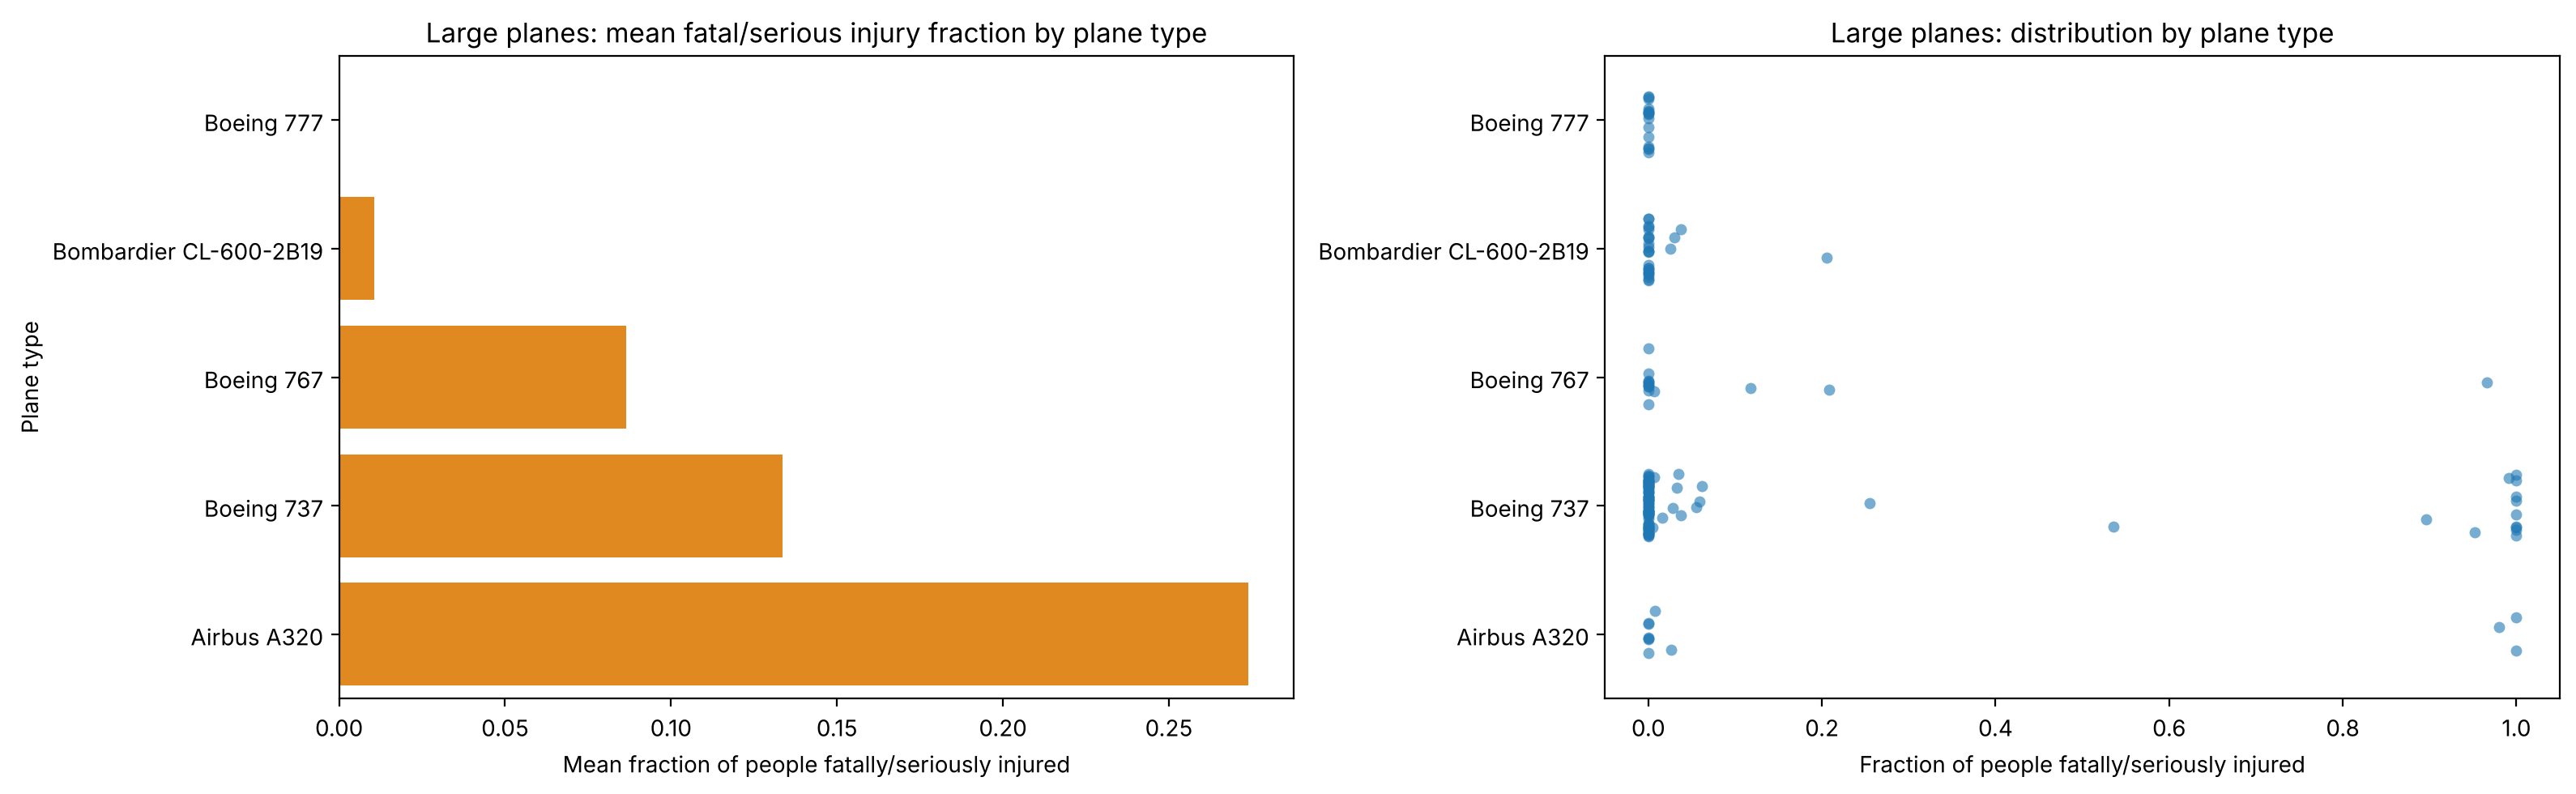

In [8]:
# Summary by plane type (Make + Model), keeping types with at least 10 accidents
def model_summary(data, min_accidents=10):
    summary = data.groupby("Make.Model").agg(
        Accidents=("Event.Id", "count"),
        Mean_Fatal_Serious=("Fatal.Serious.Fraction", "mean"),
        Destroyed_Rate=("Destroyed", "mean"),
    )
    return summary[summary["Accidents"] >= min_accidents].sort_values("Mean_Fatal_Serious")

large_models = model_summary(large)
display(large_models.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Mean fatal/serious injury fraction by plane type
sns.barplot(x=large_models["Mean_Fatal_Serious"], y=large_models.index, ax=axes[0], color="darkorange")
axes[0].set_title("Large planes: mean fatal/serious injury fraction by plane type")
axes[0].set_xlabel("Mean fraction of people fatally/seriously injured")
axes[0].set_ylabel("Plane type")

# Distribution: each dot is one accident
sns.stripplot(data=large[large["Make.Model"].isin(large_models.index)],
              x="Fatal.Serious.Fraction", y="Make.Model", order=large_models.index,
              jitter=0.25, alpha=0.6, ax=axes[1])
axes[1].set_title("Large planes: distribution by plane type")
axes[1].set_xlabel("Fraction of people fatally/seriously injured")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

Small plane types with at least 10 accidents: 714


,Accidents,Mean_Fatal_Serious,Destroyed_Rate
Make.Model,,,
Piper PA-18A 150,12,0.000,0.000
Diamond DA 20 C1,11,0.000,0.000
Grumman G164B,18,0.000,0.167
Cessna 180C,15,0.000,0.067
Maule MX-7-235,17,0.029,0.000
Cessna C172,12,0.042,0.000
North American AT-6G,11,0.045,0.000
Beech 1900D,43,0.047,0.047
Piper PA-18-160,31,0.048,0.032


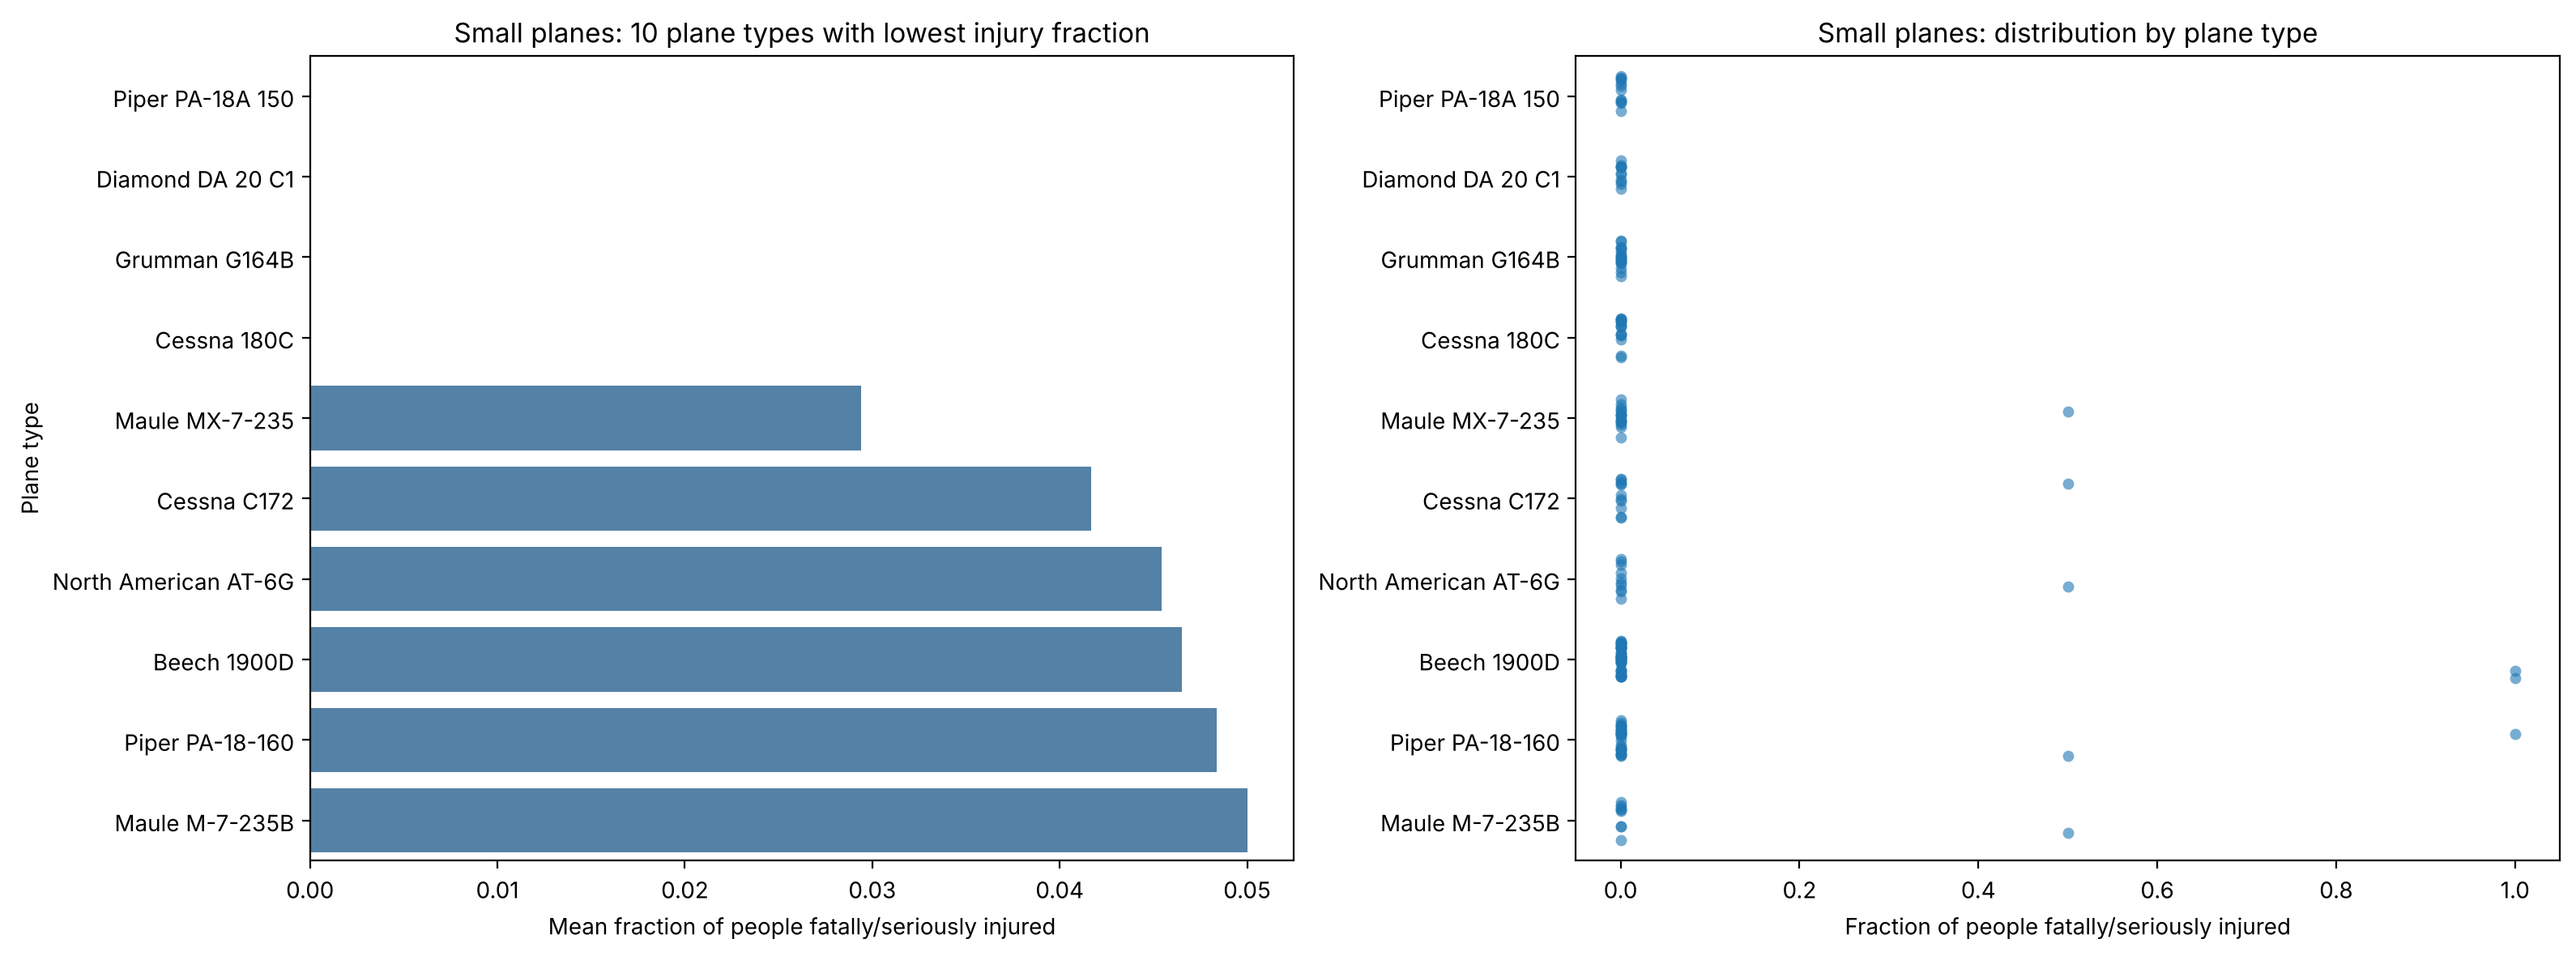

In [9]:
# Small planes: plane types with at least 10 accidents, 10 lowest injury fractions
small_models = model_summary(small)
print("Small plane types with at least 10 accidents:", len(small_models))

small_top10_models = small_models.head(10)
display(small_top10_models.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Mean fatal/serious injury fraction by plane type
sns.barplot(x=small_top10_models["Mean_Fatal_Serious"], y=small_top10_models.index,
            ax=axes[0], color="steelblue")
axes[0].set_title("Small planes: 10 plane types with lowest injury fraction")
axes[0].set_xlabel("Mean fraction of people fatally/seriously injured")
axes[0].set_ylabel("Plane type")

# Distribution: each dot is one accident
sns.stripplot(data=small[small["Make.Model"].isin(small_top10_models.index)],
              x="Fatal.Serious.Fraction", y="Make.Model", order=small_top10_models.index,
              jitter=0.25, alpha=0.6, ax=axes[1])
axes[1].set_title("Small planes: distribution by plane type")
axes[1].set_xlabel("Fraction of people fatally/seriously injured")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Discussion: specific plane types

**Large aircraft**
- Only five large plane types have at least 10 accidents, so the choice is limited but clear.
- The **Boeing 777** had no fatal or serious injuries in any of its 16 accidents, and a low destruction rate (≈0.06).
- The **Bombardier CL-600-2B19** (a regional jet) had almost no serious injuries (≈0.01) and was never destroyed in 28 accidents.
- The **Boeing 737** is the most reliable estimate (97 accidents): injury fraction ≈0.13 and destruction rate ≈0.11, low overall but with a few severe crashes visible in the distribution plot.
- The **Airbus A320** performs worst (≈0.27 injury, ≈0.27 destroyed), but on only 11 accidents.
- **Recommendation:** Boeing 777 and Bombardier CL-600-2B19 for large passenger aircraft, with the Boeing 737 as a well-documented, solid option.

**Small aircraft**
- 714 small plane types have at least 10 accidents. The ten best all have mean injury fractions below 0.05.
- Four types had no fatal or serious injuries at all: **Diamond DA 20 C1**, **Piper PA-18A 150**, **Cessna 180C** and **Grumman G164B**.
- The **Beech 1900D** is the most robust result (43 accidents, ≈0.05 injury, ≈0.05 destroyed). It is a 19-seat commuter plane, sitting just under the 20-person threshold.
- **Maule** appears twice in the top ten (MX-7-235 and M-7-235B), consistent with Maule being one of the safest small makes overall.
- The Grumman G164B is an agricultural crop-duster with a higher destruction rate (≈0.17), so it suits a different use case than passenger transport.
- **Recommendation:** Beech 1900D, Diamond DA 20 C1, Maule MX-7 series and Piper PA-18 series for small aircraft.

**Caveat:** sample sizes per plane type are small (10–43 accidents for most), so these model-level results are less certain than the make-level results. Sub-variants (e.g. Cessna 172 vs 172N) are counted separately, which splits some samples.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

,Accidents,Mean_Fatal_Serious,Destroyed_Rate
Weather.Condition,,,
IMC,4531,0.683,0.598
VMC,50960,0.223,0.169


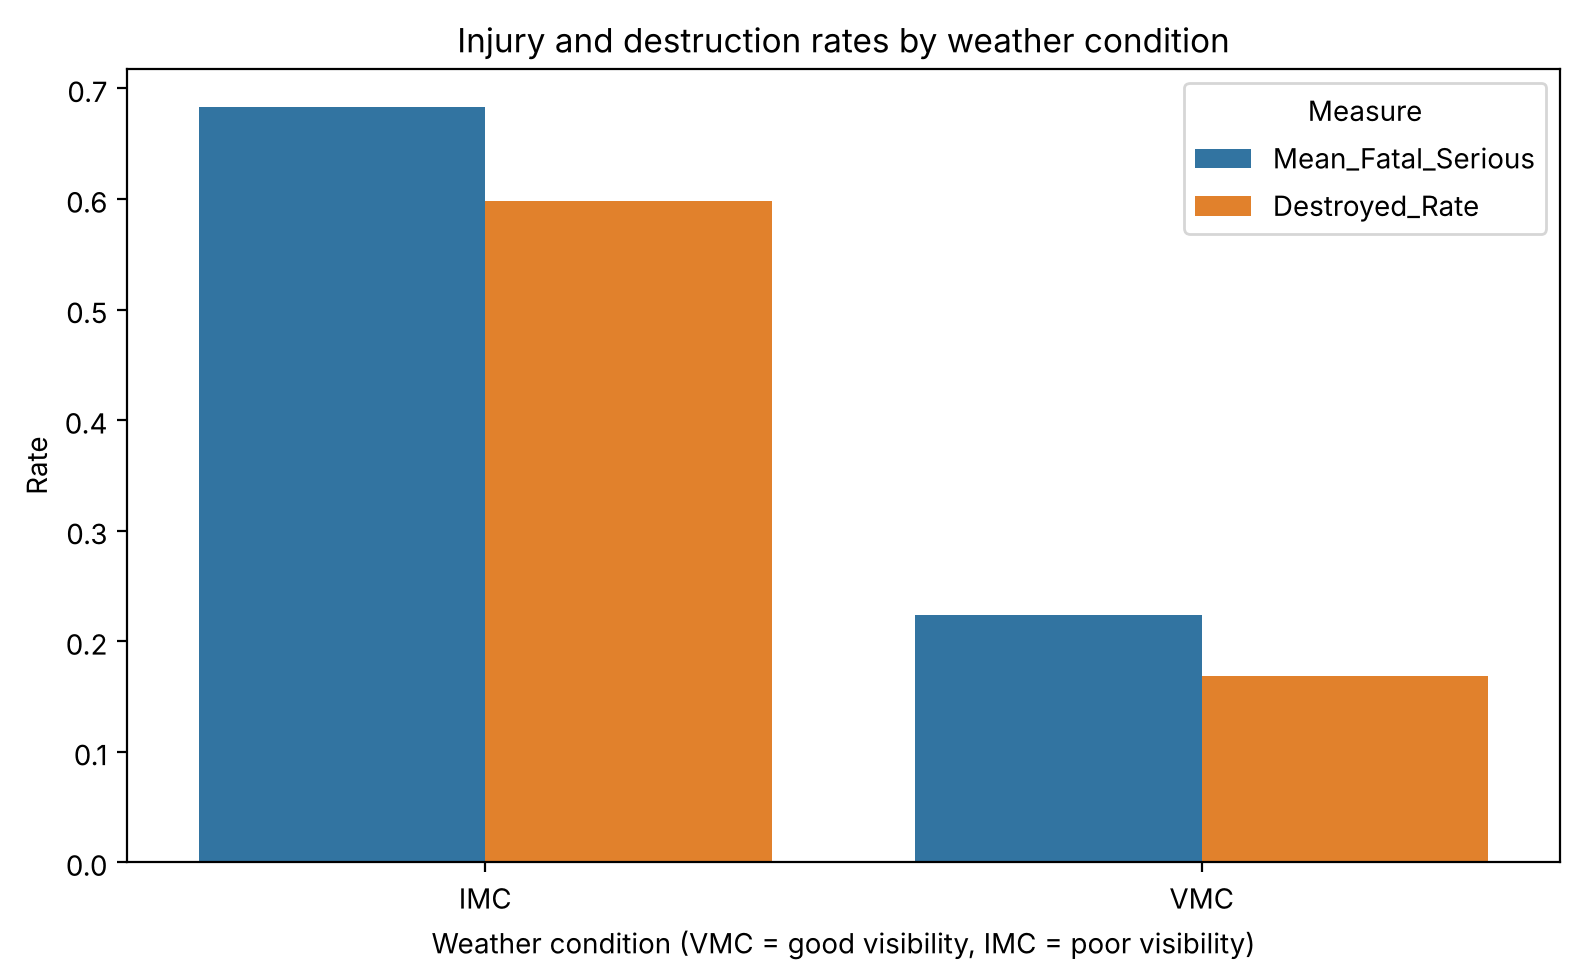

In [10]:
# --- Factor 1: Weather Condition ---
# VMC = Visual Meteorological Conditions (good visibility)
# IMC = Instrument Meteorological Conditions (poor visibility, flying by instruments)
weather = df.dropna(subset=["Weather.Condition"]).groupby("Weather.Condition").agg(
    Accidents=("Event.Id", "count"),
    Mean_Fatal_Serious=("Fatal.Serious.Fraction", "mean"),
    Destroyed_Rate=("Destroyed", "mean"),
)
display(weather.round(3))

# Side-by-side bars for injury fraction and destruction rate
weather_plot = weather[["Mean_Fatal_Serious", "Destroyed_Rate"]].reset_index().melt(
    id_vars="Weather.Condition", var_name="Measure", value_name="Rate")

plt.figure(figsize=(8, 5))
sns.barplot(data=weather_plot, x="Weather.Condition", y="Rate", hue="Measure")
plt.title("Injury and destruction rates by weather condition")
plt.xlabel("Weather condition (VMC = good visibility, IMC = poor visibility)")
plt.ylabel("Rate")
plt.tight_layout()
plt.show()

### Factor 1: Weather condition

- Accidents in **IMC** (poor visibility, instrument conditions) are far more severe than in **VMC** (good visibility).
- In IMC, the mean fatal/serious injury fraction is ≈0.68 and ≈60% of aircraft are destroyed, compared with ≈0.22 and ≈17% in VMC: roughly **3 times higher** on both measures.
- Both groups have large samples (4,531 IMC and 50,960 VMC accidents), so the difference is robust.
- **Implication for the client:** operations in poor-visibility conditions carry much higher risk. Pilot instrument training, aircraft equipped for instrument flight, and weather-related operating policies should factor into insurance pricing.

,Accidents,Mean_Fatal_Serious,Destroyed_Rate
Broad.phase.of.flight,,,
Taxi,1332,0.017,0.022
Landing,11647,0.035,0.043
Standing,446,0.087,0.137
Takeoff,8620,0.229,0.220
Go-around,1148,0.301,0.289
Descent,1216,0.349,0.334
Cruise,6960,0.354,0.346
Approach,4422,0.355,0.302
Climb,1352,0.432,0.436


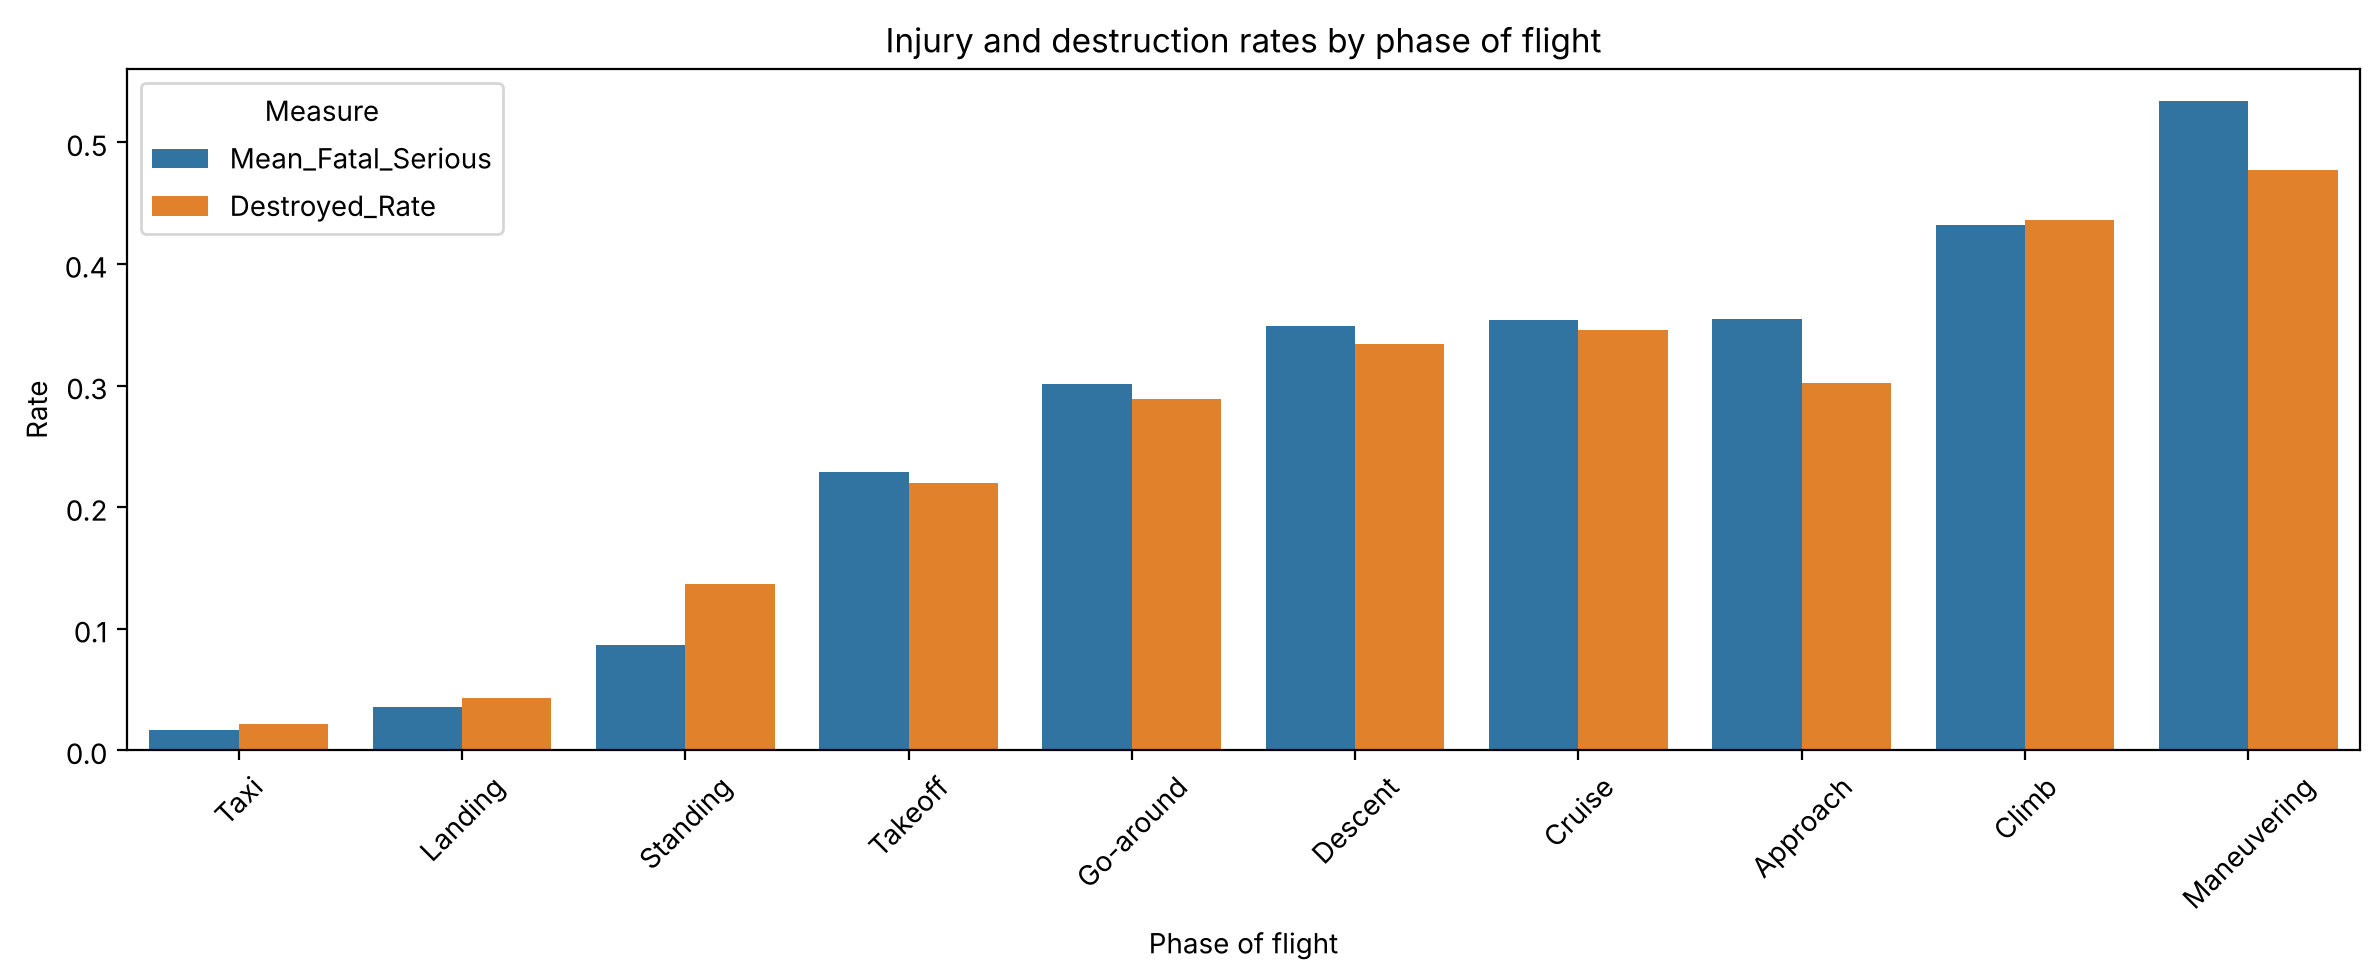

In [11]:
# --- Factor 2: Broad phase of flight ---
phase = df.dropna(subset=["Broad.phase.of.flight"]).groupby("Broad.phase.of.flight").agg(
    Accidents=("Event.Id", "count"),
    Mean_Fatal_Serious=("Fatal.Serious.Fraction", "mean"),
    Destroyed_Rate=("Destroyed", "mean"),
).sort_values("Mean_Fatal_Serious")
display(phase.round(3))

phase_plot = phase[["Mean_Fatal_Serious", "Destroyed_Rate"]].reset_index().melt(
    id_vars="Broad.phase.of.flight", var_name="Measure", value_name="Rate")

plt.figure(figsize=(12, 5))
sns.barplot(data=phase_plot, x="Broad.phase.of.flight", y="Rate", hue="Measure", order=phase.index)
plt.title("Injury and destruction rates by phase of flight")
plt.xlabel("Phase of flight")
plt.ylabel("Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Factor 2: Phase of flight

- Accident severity depends strongly on when the accident happens.
- **Ground and low-speed phases are the least severe:** Taxi (≈0.02 injury fraction) and Landing (≈0.04) rarely cause serious injuries, even though Landing has the most accidents (11,647).
- **Airborne phases at speed or altitude are the most severe:** Maneuvering (≈0.53 injury, ≈48% destroyed), Climb (≈0.43), Cruise and Approach (≈0.35).
- Every phase has over 400 accidents, so the comparisons are reliable; note that phase of flight is missing for about 16,000 records.
- **Implication for the client:** the *number* of accidents and their *severity* tell different stories. Landing accidents are common but mostly minor, while maneuvering and climb accidents are rarer but much more likely to be fatal. Operations involving low-altitude maneuvering (e.g. aerial application, aerobatics) carry higher risk.